## Импорт библиотек

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

## Подготовка данных

In [2]:
df = pd.read_csv("insurance.csv")
df = df.fillna(df.median(numeric_only=True))

df = pd.get_dummies(df, drop_first=True)

X = df.drop("charges", axis=1)
y = df["charges"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(X_train.shape)

(1070, 8)

**Вывод по подготовке данных.** Категориальные признаки `sex`, `smoker` и `region` закодированы через One-Hot Encoding, а `drop_first=True` убирает лишний столбец и не даёт признакам дублировать друг друга. Масштабирование `StandardScaler` обучено только на обучающей выборке и затем применено к тестовой.

## Классификация: логистическая регрессия

In [3]:
from IPython.display import display
median_price = y_train.median()
y_train_class = (y_train>median_price).astype(int)
y_test_class = (y_test>median_price).astype(int)

clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train, y_train_class)

sample_probs = clf.predict_proba(X_test[:5])[:, 1]
sample_preds = clf.predict(X_test[:5])
display(
    pd.DataFrame(
        {
            "Вероятность (Сигмоида)":sample_probs,
            "Класс (Порог 0.5)":sample_preds,
            "Факт":y_test_class.iloc[:5].values
        }
    )
)
print(f"Точность классификации (Accuracy): {accuracy_score(y_test_class, clf.predict(X_test)):.4f}")

,Вероятность (Сигмоида),Класс (Порог 0.5),Факт
0,0.557703,1,0
1,0.189830,0,0
2,0.999977,1,1
3,0.485211,0,0
4,0.977975,1,1


Точность классификации (Accuracy): 0.9104

**Вывод по классификации.** Модель справляется заметно лучше случайного выбора: Accuracy высокая, то есть подавляющее большинство клиентов относится к верной группе затрат. Там, где вероятность близка к нулю или к единице, модель уверена и не ошибается, а ошибки возможны около порога 0.5, где классы трудно разделить. В показанной выборке единственная ошибка пришлась именно на такой пограничный случай.

## Регрессия: МНК и SGD

In [4]:
start_ols = time.time()
ols = LinearRegression()
ols.fit(X_train, y_train)
time_ols = time.time() - start_ols
pred_ols = ols.predict(X_test)

start_sgd = time.time()
sgd = SGDRegressor(
    max_iter=1000,
    tol=1e-3,
    eta0=0.01,
    learning_rate="adaptive",
    random_state=42
)
sgd.fit(X_train, y_train)
time_sgd = time.time() - start_sgd
pred_sgd = sgd.predict(X_test)

rmse_ols = np.sqrt(mean_squared_error(y_test, pred_ols))
r2_ols = r2_score(y_test, pred_ols)

rmse_sgd = np.sqrt(mean_squared_error(y_test, pred_sgd))
r2_sgd = r2_score(y_test, pred_sgd)

print(f"МНК (Аналитический): RMSE = ${rmse_ols:,.2f} | R2 = {r2_ols:.2f} | Время = {time_ols:.5f} сек")
print(f"SGD (Итеративный): RMSE = ${rmse_sgd:,.2f} | R2 = {r2_sgd:.2f} | Время = {time_sgd:.5f} сек")

МНК (Аналитический): RMSE = $5,796.28 | R2 = 0.78 | Время = 0.00117 сек
SGD (Итеративный): RMSE = $5,796.14 | R2 = 0.78 | Время = 0.05140 сек

**Вывод по сравнению МНК и SGD.** Оба метода дают практически одинаковое качество: ошибки RMSE почти совпадают, а R² показывает, что модель объясняет большую часть разброса расходов. SGD сошёлся к тому же решению, которое МНК находит аналитически, во многом благодаря масштабированию признаков. По скорости на этих данных МНК выигрывает: таблица небольшая, а признаков немного, поэтому матричное решение считается почти мгновенно. Преимущество SGD проявляется на очень больших данных, где работа с матрицей становится слишком дорогой по времени и памяти.

## Визуализация и экономическая интерпретация

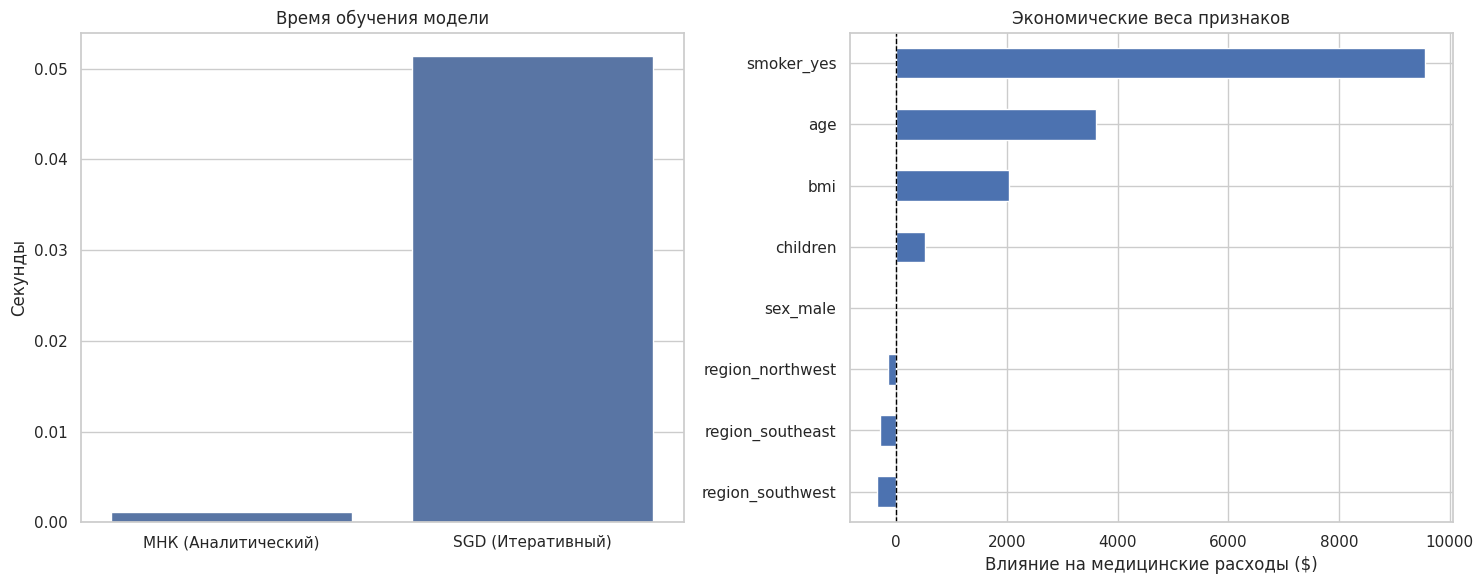

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
# 1. Сравнение времени выполнения
sns.barplot(
    x=["МНК (Аналитический)", "SGD (Итеративный)"],
    y=[time_ols, time_sgd],
    ax=axes[0]
)
axes[0].set_title("Время обучения модели")
axes[0].set_ylabel("Секунды")

weights = pd.Series(ols.coef_, index=X.columns).sort_values()
weights.plot(kind="barh", ax=axes[1])
axes[1].set_title("Экономические веса признаков")
axes[1].set_xlabel("Влияние на медицинские расходы ($)")
axes[1].axvline(0, color="black", linestyle="--", lw=1)

plt.tight_layout()
plt.show()

**Вывод по графикам.** Левый график подтверждает, что МНК обучается быстрее SGD, а правый показывает веса признаков. Так как признаки стандартизированы, веса сопоставимы между собой: чем длиннее столбец, тем сильнее признак влияет на расходы.